# Amplitude Amplification — Grover Diffusion Operator (Qiskit)

**Chapter / concept:** Amplitude Amplification, Grover Operator `G = D · O`

**Circuit:** 2-qubit Grover search. Oracle marks the state `|11>`. One full Grover
iteration `G = D · O` is applied on top of the uniform superposition `H⊗H |00>`.

## SETUP (identical in the matched CUDA-Q notebook)
- **N_QUBITS** = 2
- **Gate sequence:**
  1. `H(q0)`, `H(q1)` — prepare uniform superposition `|s>`
  2. **Oracle O:** `CZ(q0,q1)` — flips the phase of `|11>` only
  3. **Diffusion D:** `H(q0)`, `H(q1)`, `X(q0)`, `X(q1)`, `CZ(q0,q1)`, `X(q0)`, `X(q1)`,
     `H(q0)`, `H(q1)` — reflection about the mean (`2|s><s| - I`, up to global phase)
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring
  (Qiskit's native convention — no reversal needed in this notebook).
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `abs(amp) > 1e-9`,
  in ascending bitstring order, is rotated to be real and positive.
- **Basis ordering for matrices:** `{|00>, |01>, |10>, |11>}`, ascending binary order.

## Theory recap
For `N = 4` basis states with `M = 1` marked state, `sin(theta) = sqrt(M/N) = 1/2`,
so `theta = 30 deg`. After `k` Grover iterations the marked-state probability is
`sin((2k+1) * theta)^2`. For `k = 1`: `sin(90 deg)^2 = 1`, i.e. **the marked state
`|11>` is found with probability 1 after exactly one iteration** — this is the
well-known exact case for a 4-item search space with 1 marked item.

Diffuser identity used for cross-checking: the circuit `H^⊗2 X^⊗2 CZ X^⊗2 H^⊗2`
implements `2|s><s| - I` **up to an overall global phase of -1** (i.e. it equals
`I - 2|s><s|`). This is a known artifact of the standard "H-X-CZ-X-H" diffuser
construction and does not affect any measured probability — the global-phase
normalization step below removes it for the statevector comparison.

**Run all cells top to bottom.**


In [1]:
# Install (uncomment if running in a fresh environment)
# pip install -q qiskit qiskit-aer pylatexenc
# NOTE: package name is "qiskit-aer" (import as qiskit_aer.AerSimulator).
# pylatexenc is only needed for circuit.draw(output="mpl") gate-label rendering.


In [4]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 6.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 83.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.1 MB/s eta 0:00:00


In [5]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

N_QUBITS = 2
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "grover_2q_diffusion"

print(f"N_QUBITS = {N_QUBITS}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")


N_QUBITS = 2
SHOTS    = 10000
SEED     = 42


In [6]:
# Build the circuit gate-by-gate.
# Qiskit convention: qubit 0 is the LEAST-significant (rightmost) bit in bitstrings
# and counts dictionaries — this matches our QUBIT ORDERING CONTRACT with no changes.

qc = QuantumCircuit(N_QUBITS, name="Grover_1_iteration")

# --- State preparation: build the uniform superposition |s> ---
qc.h(0)   # qubit 0 -> equal superposition of |0> and |1>
qc.h(1)   # qubit 1 -> equal superposition of |0> and |1>
qc.barrier(label="|s>")

# --- Oracle O: mark |11> by flipping its phase ---
qc.cz(0, 1)   # CZ leaves |00>,|01>,|10> unchanged and sends |11> -> -|11>
qc.barrier(label="Oracle")

# --- Diffusion operator D = H^2 X^2 CZ X^2 H^2 (reflection about the mean) ---
qc.h(0); qc.h(1)          # map |s> -> |00...0>
qc.x(0); qc.x(1)          # map |00...0> -> |11...1>
qc.cz(0, 1)                # phase-flip |11...1> (== phase flip of |00...0> pre-X)
qc.x(0); qc.x(1)          # undo the X layer
qc.h(0); qc.h(1)          # undo the H layer
qc.barrier(label="Diffusion")

print(qc)


     ┌───┐ |s>     Oracle ┌───┐┌───┐   ┌───┐┌───┐ Diffusion 
q_0: ┤ H ├──░───■────░────┤ H ├┤ X ├─■─┤ X ├┤ H ├─────░─────
     ├───┤  ░   │    ░    ├───┤├───┤ │ ├───┤├───┤     ░     
q_1: ┤ H ├──░───■────░────┤ H ├┤ X ├─■─┤ X ├┤ H ├─────░─────
     └───┘  ░        ░    └───┘└───┘   └───┘└───┘     ░     


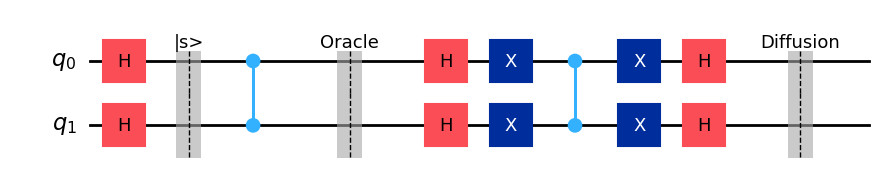

In [7]:
# Draw the circuit with matplotlib and save it.
fig = qc.draw(output="mpl", style={"name": "iqp"})
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", bbox_inches="tight", dpi=150)
fig


In [8]:
# Explicit matrix representation, built two independent ways and cross-checked.
np.set_printoptions(precision=4, suppress=True)

# --- (a) Hand-built from individual gate matrices (NumPy), ascending-binary basis ---
I2 = np.eye(2)
H1 = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])
X1 = np.array([[0, 1], [1, 0]])

def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

# Basis convention {|00>,|01>,|10>,|11>} read as |q1 q0> (qubit 0 = rightmost bit),
# matching Qiskit's own little-endian tensor ordering, so H(0)*H(1) in circuit order
# corresponds to kron(H_q1, H_q0) = kron(H, H) here since H⊗H is symmetric.
Hn = kron_all([H1, H1])
Xn = kron_all([X1, X1])
CZ = np.eye(4)
CZ[3, 3] = -1   # flips |11> (index 3 in ascending-binary basis)

Oracle_hand = CZ.copy()
Diffusion_hand = Hn @ Xn @ CZ @ Xn @ Hn
Grover_hand = Diffusion_hand @ Oracle_hand

print("Oracle O (hand-built):\n", Oracle_hand)
print("\nDiffusion D (hand-built):\n", Diffusion_hand)
print("\nGrover operator G = D.O (hand-built):\n", Grover_hand)

# --- (b) Extracted directly from the Qiskit circuit via Operator() ---
oracle_qc = QuantumCircuit(N_QUBITS)
oracle_qc.cz(0, 1)
Oracle_qiskit = Operator(oracle_qc).data

diffusion_qc = QuantumCircuit(N_QUBITS)
diffusion_qc.h(0); diffusion_qc.h(1)
diffusion_qc.x(0); diffusion_qc.x(1)
diffusion_qc.cz(0, 1)
diffusion_qc.x(0); diffusion_qc.x(1)
diffusion_qc.h(0); diffusion_qc.h(1)
Diffusion_qiskit = Operator(diffusion_qc).data

Grover_qiskit = Diffusion_qiskit @ Oracle_qiskit

print("\nOracle matches (hand vs Qiskit Operator):", np.allclose(Oracle_hand, Oracle_qiskit))
print("Diffusion matches (hand vs Qiskit Operator):", np.allclose(Diffusion_hand, Diffusion_qiskit))
print("Grover operator matches (hand vs Qiskit Operator):", np.allclose(Grover_hand, Grover_qiskit))

assert np.allclose(Oracle_hand, Oracle_qiskit)
assert np.allclose(Diffusion_hand, Diffusion_qiskit)
assert np.allclose(Grover_hand, Grover_qiskit)


Oracle O (hand-built):
 [[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]]

Diffusion D (hand-built):
 [[ 0.5 -0.5 -0.5 -0.5]
 [-0.5  0.5 -0.5 -0.5]
 [-0.5 -0.5  0.5 -0.5]
 [-0.5 -0.5 -0.5  0.5]]

Grover operator G = D.O (hand-built):
 [[ 0.5 -0.5 -0.5  0.5]
 [-0.5  0.5 -0.5  0.5]
 [-0.5 -0.5  0.5  0.5]
 [-0.5 -0.5 -0.5 -0.5]]

Oracle matches (hand vs Qiskit Operator): True
Diffusion matches (hand vs Qiskit Operator): True
Grover operator matches (hand vs Qiskit Operator): True


In [10]:
# Exact statevector, with global-phase normalization applied.

def normalize_global_phase(vec):
    vec = np.asarray(vec, dtype=complex)
    idx = np.argmax(np.abs(vec) > 1e-9)   # first index (ascending order) with nonzero amp
    phase = np.angle(vec[idx])
    return vec * np.exp(-1j * phase)

sv_circuit = qc.copy()   # no measurements yet
sv = Statevector.from_instruction(sv_circuit).data

# Qiskit already indexes amplitudes with qubit 0 as the rightmost bit -> no reversal needed.
sv_normalized = normalize_global_phase(sv)

probs_qiskit_sv = {format(i, f"0{N_QUBITS}b"): float(abs(sv_normalized[i]) ** 2)
                    for i in range(2 ** N_QUBITS)}
probs_qiskit_sv = dict(sorted(probs_qiskit_sv.items()))

print("Statevector (phase-normalized):", sv_normalized)
print("\nProbability dictionary (statevector):")
for k, v in probs_qiskit_sv.items():
    print(f"  |{k}> : {v:.6f}")


Statevector (phase-normalized): [0.+0.j 0.+0.j 0.+0.j 1.+0.j]

Probability dictionary (statevector):
  |00> : 0.000000
  |01> : 0.000000
  |10> : 0.000000
  |11> : 1.000000


### Ordering-fix note (Qiskit)

**No bitstring reversal was applied.** Qiskit's `Statevector` and `AerSimulator`
counts both natively index qubit 0 as the least-significant (rightmost) bit, which
is exactly the QUBIT ORDERING CONTRACT defined above. This notebook's dictionaries
can be compared directly to the phase-normalized, bit-order-corrected CUDA-Q results.


In [11]:
# Measurement: add measurements, run with the shared SEED/SHOTS, get counts -> probabilities.
meas_qc = qc.copy()
meas_qc.measure_all()

sim = AerSimulator(seed_simulator=SEED)
compiled = transpile(meas_qc, sim)
job = sim.run(compiled, shots=SHOTS, seed_simulator=SEED)
result = job.result()
counts = result.get_counts()

# Qiskit's measure_all() counts keys already use qubit 0 = rightmost bit -> no reversal needed.
probs_qiskit_counts = {k: v / SHOTS for k, v in counts.items()}
probs_qiskit_counts = dict(sorted(probs_qiskit_counts.items()))

print("Raw counts:", counts)
print("\nProbabilities from sampling:")
for k, v in probs_qiskit_counts.items():
    print(f"  |{k}> : {v:.4f}")


Raw counts: {'11': 10000}

Probabilities from sampling:
  |11> : 1.0000


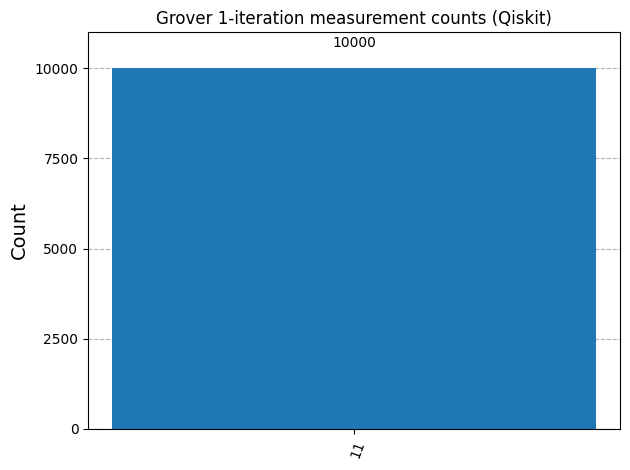

In [12]:
# Histogram (matplotlib), saved to file.
fig2 = plot_histogram(counts, title="Grover 1-iteration measurement counts (Qiskit)")
fig2.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", bbox_inches="tight", dpi=150)
fig2


In [13]:
# Resource counts.
depth = qc.depth()
gate_counts = qc.count_ops()
print(f"Circuit depth (with barriers as visual markers, before transpile): {depth}")
print(f"Gate counts: {dict(gate_counts)}")

depth_transpiled = compiled.depth()
gate_counts_transpiled = compiled.count_ops()
print(f"\nTranspiled circuit depth (as actually run on AerSimulator): {depth_transpiled}")
print(f"Transpiled gate counts: {dict(gate_counts_transpiled)}")


Circuit depth (with barriers as visual markers, before transpile): 7
Gate counts: {'h': 6, 'x': 4, 'barrier': 3, 'cz': 2}

Transpiled circuit depth (as actually run on AerSimulator): 5
Transpiled gate counts: {'barrier': 4, 'h': 2, 'u2': 2, 'measure': 2, 'cz': 1, 'rxx': 1}


In [14]:
# Convention-notes (plain text restatement).
print("Ordering fix applied: NONE. Qiskit already uses qubit 0 = rightmost bit,")
print("matching the QUBIT ORDERING CONTRACT, so no reversal was needed anywhere")
print("in this notebook (neither for the statevector nor for the measurement counts).")
print()
print("Phase convention applied: multiplied the full statevector by exp(-1j*phase),")
print("where phase = angle of the first amplitude (ascending bitstring order) with")
print("abs(amplitude) > 1e-9, so that amplitude becomes real and positive.")


Ordering fix applied: NONE. Qiskit already uses qubit 0 = rightmost bit,
matching the QUBIT ORDERING CONTRACT, so no reversal was needed anywhere
in this notebook (neither for the statevector nor for the measurement counts).

Phase convention applied: multiplied the full statevector by exp(-1j*phase),
where phase = angle of the first amplitude (ascending bitstring order) with
abs(amplitude) > 1e-9, so that amplitude becomes real and positive.


In [15]:
# Final result dictionary.
QISKIT_RESULT = probs_qiskit_counts
print("QISKIT_RESULT =", QISKIT_RESULT)


QISKIT_RESULT = {'11': 1.0}


In [16]:
# --- Diff-check block (uncomment and run after producing CUDAQ_RESULT in the matched notebook) ---
#
# Hand-computed expected result (theory, exact statevector probabilities):
#   theta = arcsin(sqrt(1/4)) = 30 deg
#   P(|11>) after 1 Grover iteration = sin(3*theta)^2 = sin(90 deg)^2 = 1.0
#   P(|00>) = P(|01>) = P(|10>) = 0.0
#
# EXPECTED_RESULT = {"00": 0.0, "01": 0.0, "10": 0.0, "11": 1.0}
#
# all_keys = set(QISKIT_RESULT) | set(CUDAQ_RESULT) | set(EXPECTED_RESULT)
# max_delta_qiskit_vs_expected = max(abs(QISKIT_RESULT.get(k, 0.0) - EXPECTED_RESULT.get(k, 0.0)) for k in all_keys)
# max_delta_qiskit_vs_cudaq    = max(abs(QISKIT_RESULT.get(k, 0.0) - CUDAQ_RESULT.get(k, 0.0)) for k in all_keys)
#
# print("Max |QISKIT_RESULT - EXPECTED_RESULT| =", max_delta_qiskit_vs_expected)
# print("Max |QISKIT_RESULT - CUDAQ_RESULT|    =", max_delta_qiskit_vs_cudaq)
#
# assert max_delta_qiskit_vs_expected < 1e-3
# assert max_delta_qiskit_vs_cudaq < 1e-3
# print("PASS: results agree within 1e-3.")
